Ноутбук для тестирования нового подхода к детекции и сегмантации - SAM2. 

Возможно, для тестирования дальнейших гипотез.

In [8]:
video_path = '/Users/glytov_ivan/Documents/Curling_project/curling_analytics/data/videos/example_4.mp4'

# Prefer the checkpoint at project root if present, else fallback to models/SAM2
base_sam2_weights_path = '/Users/glytov_ivan/Documents/Curling_project/curling_analytics/models/SAM2/weigths/sam2_b.pt'

In [9]:
# Optional installs (uncomment if missing). Avoid running during automated scripts.
# %pip install --quiet ultralytics opencv-python numpy

import os
import cv2
import numpy as np
from ultralytics import SAM

print('OpenCV:', cv2.__version__)
print('NumPy:', np.__version__)
try:
    import ultralytics
    print('Ultralytics:', ultralytics.__version__)
except Exception as e:
    print('Ultralytics import failed:', e)


OpenCV: 4.12.0
NumPy: 2.2.6
Ultralytics: 8.3.167


In [10]:
def load_sam_model(weights_path: str) -> SAM:
    if not os.path.exists(weights_path):
        raise FileNotFoundError(f'Weights not found: {weights_path}')
    # ultralytics.SAM wraps SAM models; select 'sam2_b' architecture via weights name
    model = SAM(model=weights_path)
    return model

sam_model = load_sam_model(base_sam2_weights_path)
print('SAM2 model loaded from:', base_sam2_weights_path)


SAM2 model loaded from: /Users/glytov_ivan/Documents/Curling_project/curling_analytics/models/SAM2/weigths/sam2_b.pt


In [11]:
# Configuration for detection/segmentation
output_video_path = '/Users/glytov_ivan/Documents/Curling_project/outputs/output_birdseye_sam2.mp4'

# HoughCircles parameters to propose point prompts for SAM2
hough_dp = 1.2
hough_minDist = 40
hough_param1 = 120
hough_param2 = 24
hough_minRadius = 8
hough_maxRadius = 60

# Post-filtering thresholds
min_mask_area = 150
max_mask_area = 20000
min_circularity = 0.55  # 1.0 is a perfect circle

alpha_mask_overlay = 0.35  # mask transparency

os.makedirs(os.path.dirname(output_video_path), exist_ok=True)
print('Output path:', output_video_path)


Output path: /Users/glytov_ivan/Documents/Curling_project/outputs/output_birdseye_sam2.mp4


In [12]:
def propose_point_prompts_bgr(frame_bgr: np.ndarray):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 1.2)
    circles = cv2.HoughCircles(
        gray, cv2.HOUGH_GRADIENT, dp=hough_dp, minDist=hough_minDist,
        param1=hough_param1, param2=hough_param2,
        minRadius=hough_minRadius, maxRadius=hough_maxRadius
    )
    prompts = []
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for c in circles[0, :]:
            cx, cy, r = int(c[0]), int(c[1]), int(c[2])
            prompts.append((cx, cy, r))
    return prompts


def mask_circularity(binary_mask: np.ndarray) -> float:
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return 0.0
    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    perim = cv2.arcLength(cnt, True)
    if perim <= 1e-5:
        return 0.0
    circ = 4.0 * np.pi * (area / (perim * perim))
    return float(circ)


def filter_stone_masks(masks: list) -> list:
    filtered = []
    for m in masks:
        # m is boolean mask or 0/1 float
        binary = (m.astype(np.uint8) > 0).astype(np.uint8)
        area = int(np.sum(binary))
        if area < min_mask_area or area > max_mask_area:
            continue
        circ = mask_circularity(binary)
        if circ < min_circularity:
            continue
        filtered.append(binary)
    return filtered


def draw_masks_and_centers(frame_bgr: np.ndarray, masks: list) -> np.ndarray:
    overlay = frame_bgr.copy()
    for m in masks:
        ys, xs = np.where(m > 0)
        if len(xs) == 0:
            continue
        color = (0, 255, 255)
        overlay[m > 0] = (
            (1 - alpha_mask_overlay) * overlay[m > 0] + alpha_mask_overlay * np.array(color)
        ).astype(np.uint8)
        cx, cy = int(np.mean(xs)), int(np.mean(ys))
        cv2.circle(overlay, (cx, cy), 4, (0, 0, 255), -1)
    return overlay


In [13]:
def sam2_segment_from_points(model: SAM, frame_bgr: np.ndarray, points: list) -> list:
    # The Ultralytics SAM predict API supports points prompts in the 'points' kwarg
    # points: list of (x, y) pixel coordinates
    if not points:
        return []
    # Convert to the format expected by ultralytics (list of lists)
    xy_points = [[int(x), int(y)] for (x, y, _) in points]
    results = model.predict(source=frame_bgr, points=xy_points, verbose=False)
    masks = []
    for r in results:
        # r.masks.data: [N, H, W] torch.Tensor in {0,1}
        if getattr(r, 'masks', None) is None:
            continue
        data = r.masks.data
        # detach to numpy
        m = data.cpu().numpy()
        # If multiple masks returned, extend all
        for i in range(m.shape[0]):
            masks.append(m[i].astype(np.uint8))
    return masks


First frame read: True shape:
Proposed 35 point prompts
Candidate masks: 35, stones: 10


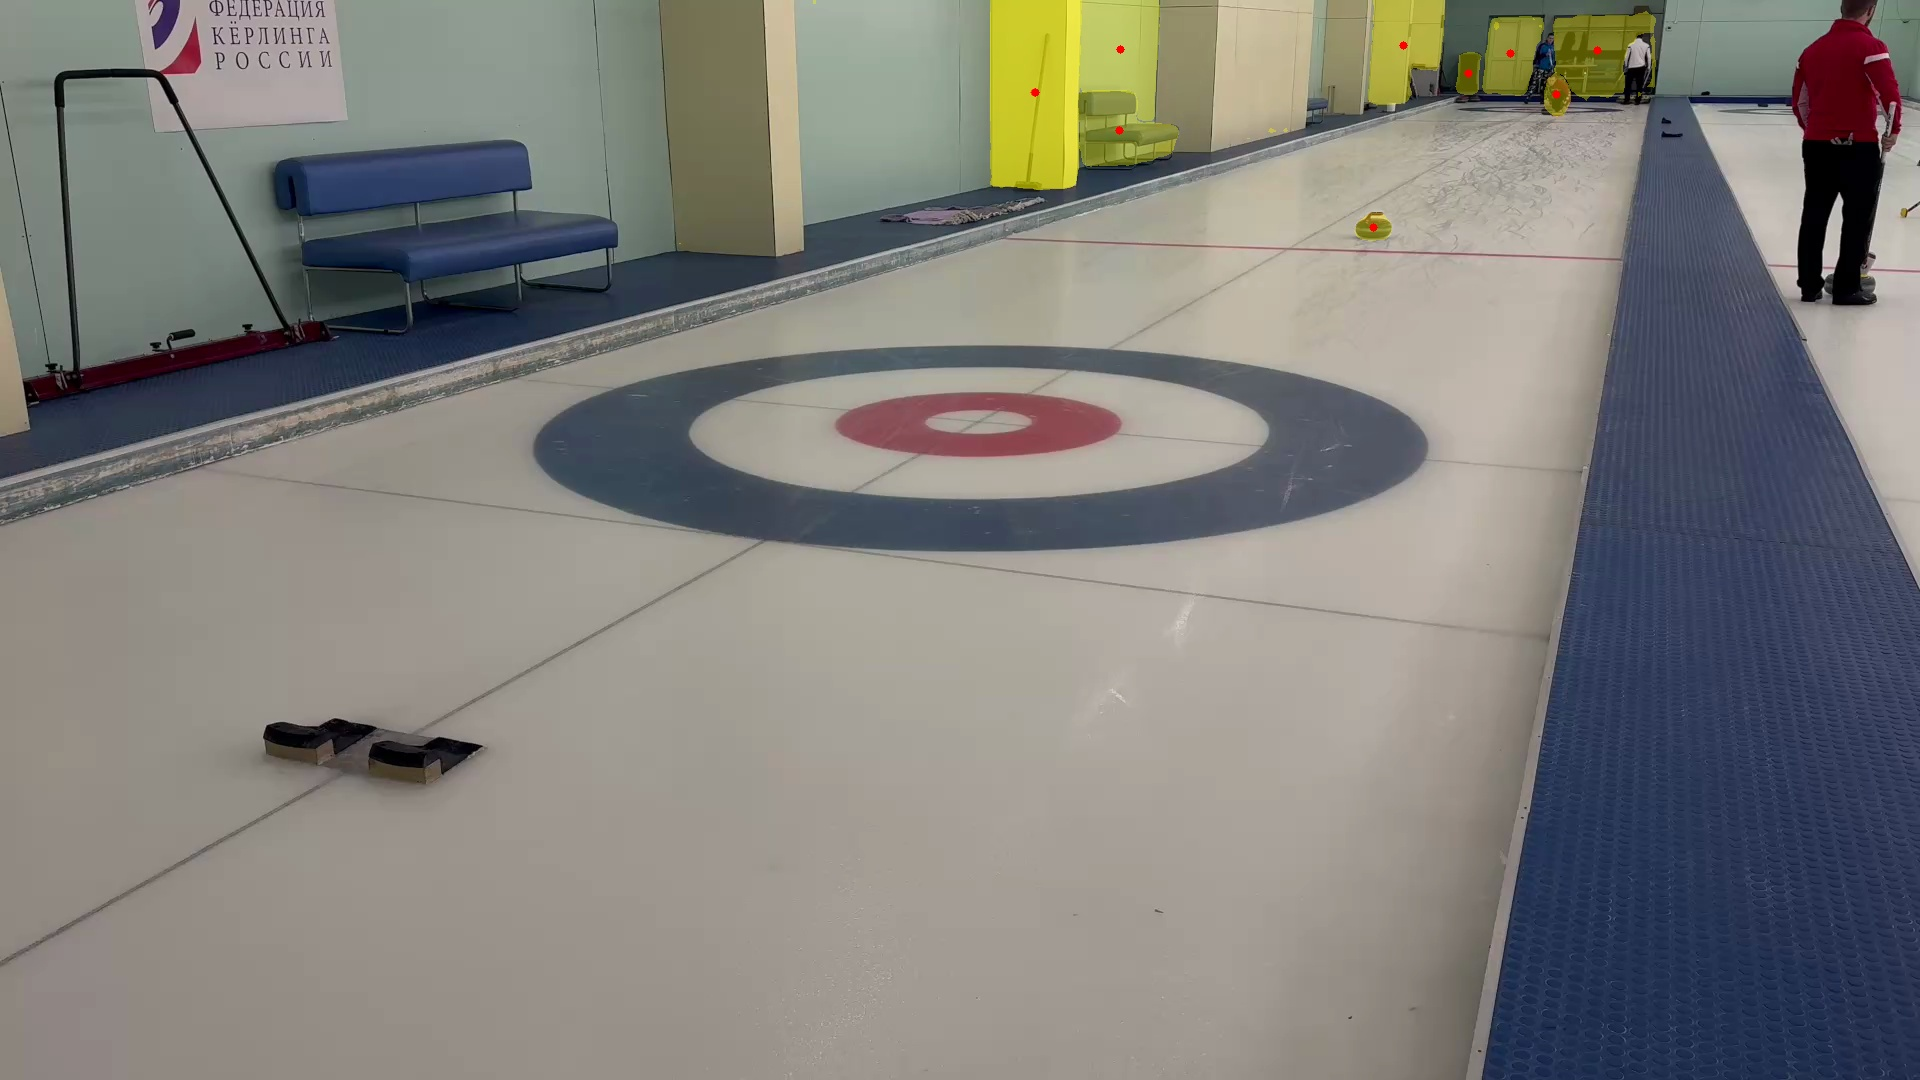

In [14]:
# Quick sanity check on one frame
cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), f'Cannot open video: {video_path}'
ok, frame = cap.read()
cap.release()
print('First frame read:', ok, 'shape:' if ok else '')

if ok:
    pts = propose_point_prompts_bgr(frame)
    print(f'Proposed {len(pts)} point prompts')
    masks = sam2_segment_from_points(sam_model, frame, pts)
    stones = filter_stone_masks(masks)
    vis = draw_masks_and_centers(frame, stones)
    print(f'Candidate masks: {len(masks)}, stones: {len(stones)}')
    # Show with OpenCV window is not ideal in notebooks; encode to JPEG and show inline
    from IPython.display import display
    import PIL.Image as Image
    _, jpg = cv2.imencode('.jpg', vis)
    display(Image.fromarray(cv2.cvtColor(cv2.imdecode(jpg, 1), cv2.COLOR_BGR2RGB)))


In [15]:
# Full video processing and save
cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), f'Cannot open video: {video_path}'

fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))

frame_idx = 0

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        prompts = propose_point_prompts_bgr(frame)
        masks = sam2_segment_from_points(sam_model, frame, prompts)
        stones = filter_stone_masks(masks)
        vis = draw_masks_and_centers(frame, stones)
        writer.write(vis)
        frame_idx += 1
        if frame_idx % 50 == 0:
            print(f'Processed {frame_idx} frames, stones in last: {len(stones)}')
finally:
    cap.release()
    writer.release()

print('Saved:', output_video_path)


Processed 50 frames, stones in last: 11
Processed 100 frames, stones in last: 12
Processed 150 frames, stones in last: 11
Processed 200 frames, stones in last: 11


KeyboardInterrupt: 